<a href="https://colab.research.google.com/github/Karthick-564/applied-deep-learning-labs/blob/main/03_optimization_algorithms/01_mnist_optimizers_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


In [ ]:
# Name: Karthick N
# Roll No:24BAD055

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, optimizers

In [ ]:
#Load and Preprocess Dataset
 (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train = x_train.reshape(-1, 784).astype('float32') / 255.0
x_test = x_test.reshape(-1, 784).astype('float32') / 255.0

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 784)
Testing data shape: (10000, 784)


In [ ]:
# Function Build Model with given Optimizer
def build_model(optimizer):
    model = keras.Sequential([
        layers.Dense(128, activation='relu', input_shape=(784,)),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [ ]:
#Train Model with SGD
model_sgd = build_model(optimizers.SGD(learning_rate=0.01))
history_sgd = model_sgd.fit(x_train, y_train,
                             validation_data=(x_test, y_test),
                             epochs=10, batch_size=128, verbose=1)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.6908 - loss: 1.2429 - val_accuracy: 0.8603 - val_loss: 0.5897
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8747 - loss: 0.4899 - val_accuracy: 0.8940 - val_loss: 0.3991
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8956 - loss: 0.3802 - val_accuracy: 0.9071 - val_loss: 0.3384
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9057 - loss: 0.3350 - val_accuracy: 0.9154 - val_loss: 0.3062
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9134 - loss: 0.3069 - val_accuracy: 0.9205 - val_loss: 0.2861
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9187 - loss: 0.2862 - val_accuracy: 0.9222 - val_loss: 0.2733
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9234 - loss: 0.2698 - val_accuracy: 0.9287 - val_loss: 0.2566
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9280 - loss: 0.2558 - val_accuracy: 0.

In [ ]:
#Training model with momentum
model_momentum = build_model(optimizers.SGD(learning_rate=0.01, momentum=0.9))
history_momentum = model_momentum.fit(x_train, y_train,
                                       validation_data=(x_test, y_test),
                                       epochs=10, batch_size=128, verbose=1)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8662 - loss: 0.4683 - val_accuracy: 0.9311 - val_loss: 0.2395
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9366 - loss: 0.2202 - val_accuracy: 0.9406 - val_loss: 0.1959
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9513 - loss: 0.1682 - val_accuracy: 0.9557 - val_loss: 0.1505
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9610 - loss: 0.1342 - val_accuracy: 0.9604 - val_loss: 0.1320
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9666 - loss: 0.1159 - val_accuracy: 0.9631 - val_loss: 0.1190
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9715 - loss: 0.0970 - val_accuracy: 0.9690 - val_loss: 0.1018
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9756 - loss: 0.0846 - val_accuracy: 0.9702 - val_loss: 0.0953
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9779 - loss: 0.0738 - val_accuracy: 0.

In [ ]:
#Training model with RMSprop
model_rmsprop = build_model(optimizers.RMSprop(learning_rate=0.001))
history_rmsprop = model_rmsprop.fit(x_train, y_train,
                                     validation_data=(x_test, y_test),
                                     epochs=10, batch_size=128, verbose=1)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9057 - loss: 0.3315 - val_accuracy: 0.9460 - val_loss: 0.1750
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9586 - loss: 0.1388 - val_accuracy: 0.9657 - val_loss: 0.1179
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9710 - loss: 0.0962 - val_accuracy: 0.9676 - val_loss: 0.1043
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9779 - loss: 0.0728 - val_accuracy: 0.9709 - val_loss: 0.0949
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9826 - loss: 0.0583 - val_accuracy: 0.9750 - val_loss: 0.0818
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9856 - loss: 0.0470 - val_accuracy: 0.9763 - val_loss: 0.0776
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9882 - loss: 0.0382 - val_accuracy: 0.9775 - val_loss: 0.0742
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9906 - loss: 0.0312 - val_accuracy: 0.

In [ ]:
#Training model with adam
model_adam = build_model(optimizers.Adam(learning_rate=0.001))
history_adam = model_adam.fit(x_train, y_train,
                               validation_data=(x_test, y_test),
                               epochs=10, batch_size=128, verbose=1)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9038 - loss: 0.3406 - val_accuracy: 0.9514 - val_loss: 0.1676
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9597 - loss: 0.1376 - val_accuracy: 0.9601 - val_loss: 0.1248
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9712 - loss: 0.0957 - val_accuracy: 0.9672 - val_loss: 0.0991
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9786 - loss: 0.0727 - val_accuracy: 0.9727 - val_loss: 0.0867
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9826 - loss: 0.0568 - val_accuracy: 0.9727 - val_loss: 0.0826
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9863 - loss: 0.0450 - val_accuracy: 0.9761 - val_loss: 0.0793
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9891 - loss: 0.0369 - val_accuracy: 0.9790 - val_loss: 0.0741
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9905 - loss: 0.0303 - val_accuracy: 0

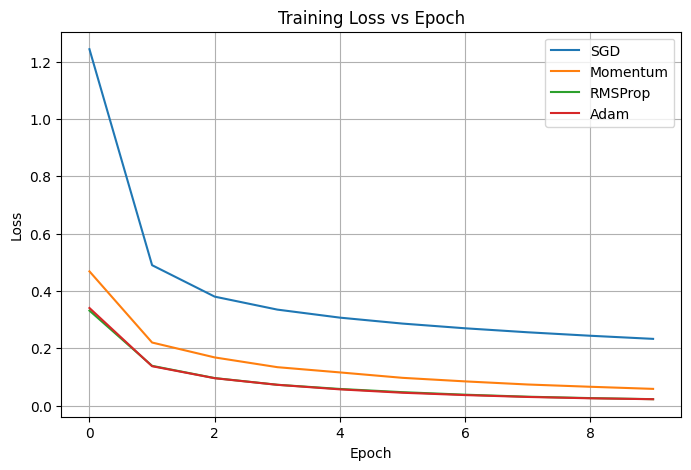

In [ ]:
#Training Loss vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history_sgd.history['loss'], label='SGD')
plt.plot(history_momentum.history['loss'], label='Momentum')
plt.plot(history_rmsprop.history['loss'], label='RMSProp')
plt.plot(history_adam.history['loss'], label='Adam')
plt.title('Training Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

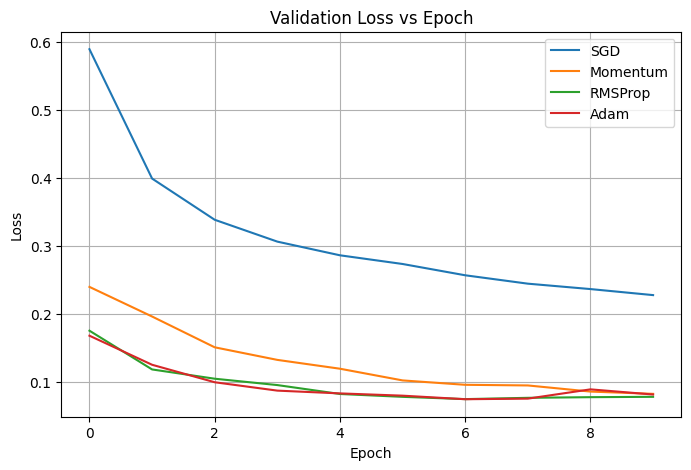

In [ ]:
#Validation Loss vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history_sgd.history['val_loss'], label='SGD')
plt.plot(history_momentum.history['val_loss'], label='Momentum')
plt.plot(history_rmsprop.history['val_loss'], label='RMSProp')
plt.plot(history_adam.history['val_loss'], label='Adam')
plt.title('Validation Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

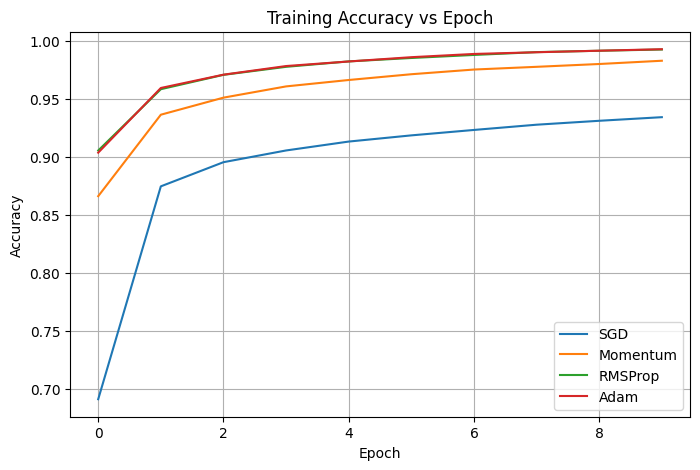

In [ ]:
#Training Accuracy vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history_sgd.history['accuracy'], label='SGD')
plt.plot(history_momentum.history['accuracy'], label='Momentum')
plt.plot(history_rmsprop.history['accuracy'], label='RMSProp')
plt.plot(history_adam.history['accuracy'], label='Adam')
plt.title('Training Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

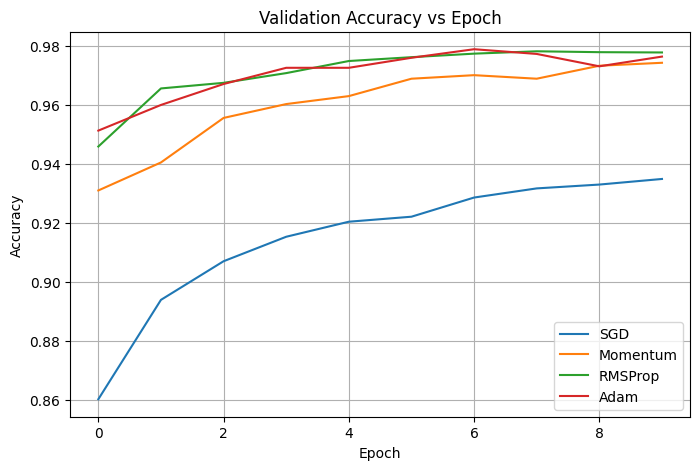

In [ ]:
#Validation Accuracy vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history_sgd.history['val_accuracy'], label='SGD')
plt.plot(history_momentum.history['val_accuracy'], label='Momentum')
plt.plot(history_rmsprop.history['val_accuracy'], label='RMSProp')
plt.plot(history_adam.history['val_accuracy'], label='Adam')
plt.title('Validation Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Final summary
print("Final Results after 10 Epochs")
print()
print(f"SGD      -> Train Acc: {history_sgd.history['accuracy'][-1]:.4f} | Val Acc: {history_sgd.history['val_accuracy'][-1]:.4f} | Train Loss: {history_sgd.history['loss'][-1]:.4f} | Val Loss: {history_sgd.history['val_loss'][-1]:.4f}")
print(f"Momentum -> Train Acc: {history_momentum.history['accuracy'][-1]:.4f} | Val Acc: {history_momentum.history['val_accuracy'][-1]:.4f} | Train Loss: {history_momentum.history['loss'][-1]:.4f} | Val Loss: {history_momentum.history['val_loss'][-1]:.4f}")
print(f"RMSProp  -> Train Acc: {history_rmsprop.history['accuracy'][-1]:.4f} | Val Acc: {history_rmsprop.history['val_accuracy'][-1]:.4f} | Train Loss: {history_rmsprop.history['loss'][-1]:.4f} | Val Loss: {history_rmsprop.history['val_loss'][-1]:.4f}")
print(f"Adam     -> Train Acc: {history_adam.history['accuracy'][-1]:.4f} | Val Acc: {history_adam.history['val_accuracy'][-1]:.4f} | Train Loss: {history_adam.history['loss'][-1]:.4f} | Val Loss: {history_adam.history['val_loss'][-1]:.4f}")

Final Results after 10 Epochs

SGD      -> Train Acc: 0.9344 | Val Acc: 0.9350 | Train Loss: 0.2329 | Val Loss: 0.2274
Momentum -> Train Acc: 0.9832 | Val Acc: 0.9744 | Train Loss: 0.0585 | Val Loss: 0.0820
RMSProp  -> Train Acc: 0.9929 | Val Acc: 0.9779 | Train Loss: 0.0226 | Val Loss: 0.0776
Adam     -> Train Acc: 0.9931 | Val Acc: 0.9765 | Train Loss: 0.0224 | Val Loss: 0.0810
